In [1]:
words = open("data/names.txt", "r").read().splitlines()

Input is a long list of names, ~32k long.

Predicting sequences of characters to generate new strings which are name-like.

Bigram makes predictions use bigrams, or pairs of characters. Given a known initial character, the following character is predicted. Essentially we are working with conditional predictions. 

In [2]:
# count the instances of the bigrams (two character tuples, overlapping)
b = {}
for w in words:
    # include start and end tokens
    chs = ["<S>"] + list(w) + ["<E>"]
    for ch1, ch2 in zip(chs, chs[1:]):
        bigram = (ch1, ch2)
        b[bigram] = b.get(bigram, 0) + 1
# sorted(b.items(), key = lambda kv: -kv[1])

In [3]:
import torch

In [4]:
# use arrays insteady of dictionaries
# 26 letters, plus start/end character
N = torch.zeros((27,27), dtype=torch.int32)

# numerical values for the characters in stoi = string-to-index
chars = sorted(list(set("".join(words)))) # all 26 letters
stoi = {s:i+1 for i,s in enumerate(chars)}
stoi["."] = 0
itos = {i:s for s, i in stoi.items()} # index-to-string

In [5]:
for w in words:
    # include start/end tokens
    chs = ["."] + list(w) + ["."]
    for ch1, ch2 in zip(chs, chs[1:]):
        ix1 = stoi[ch1]
        ix2 = stoi[ch2]
        N[ix1, ix2] += 1

Using matplotlib backend: module://matplotlib_inline.backend_inline


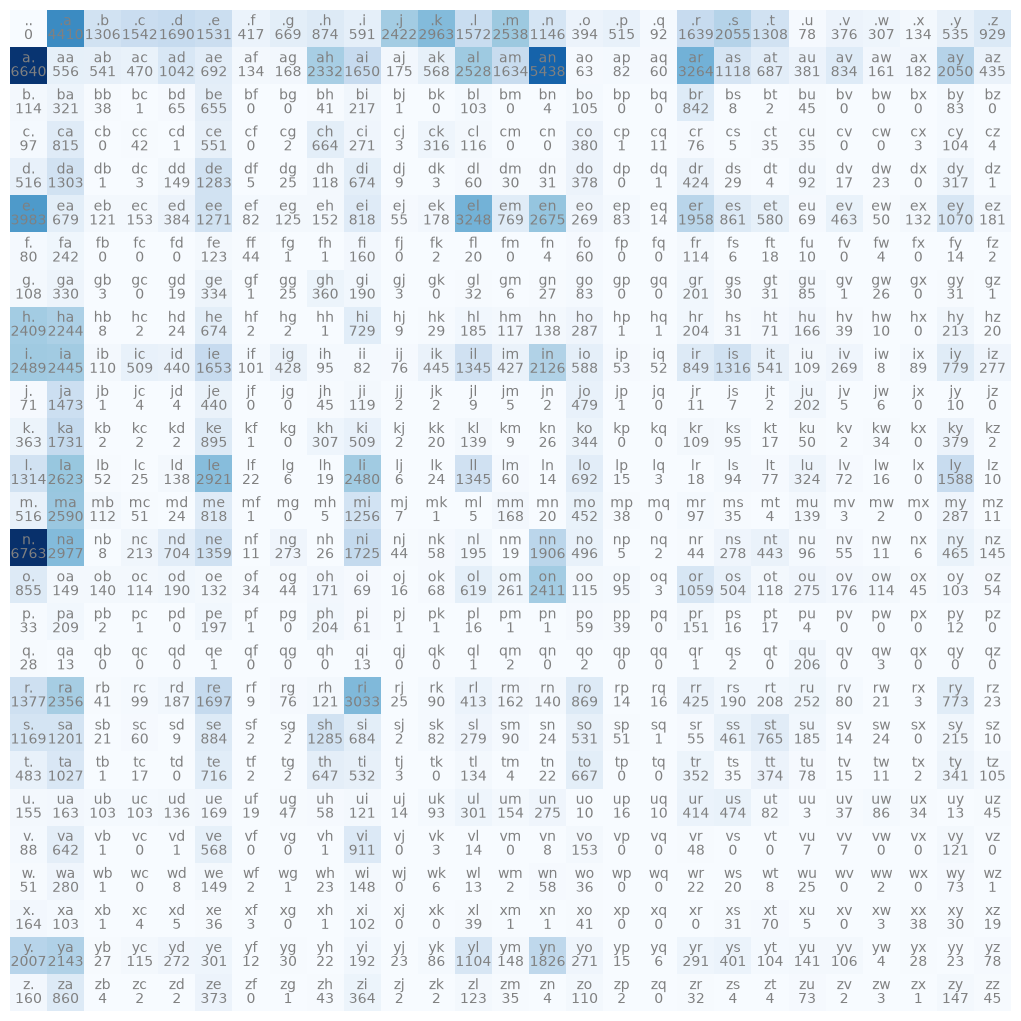

In [6]:
import matplotlib.pyplot as plt
%matplotlib

plt.figure(figsize=(13,13))
plt.imshow(N, cmap="Blues")
for i in range(27):
    for j in range(27):
        chstr = itos[i] + itos[j]
        plt.text(j, i, chstr, ha="center", va="bottom", color="gray")
        plt.text(j, i, N[i, j].item(), ha="center", va="top", color="gray")
    plt.axis("off")

In [7]:
# Convert the count row into a probability (just like Markov models!)
p = N[0].float()
p = p / p.sum()
p

tensor([0.0000, 0.1377, 0.0408, 0.0481, 0.0528, 0.0478, 0.0130, 0.0209, 0.0273,
        0.0184, 0.0756, 0.0925, 0.0491, 0.0792, 0.0358, 0.0123, 0.0161, 0.0029,
        0.0512, 0.0642, 0.0408, 0.0024, 0.0117, 0.0096, 0.0042, 0.0167, 0.0290])

In [8]:
# Use the probability distribution from row 1, to chose a letter
g = torch.Generator().manual_seed(67)
ix = torch.multinomial(p, num_samples=1, replacement=True, generator=g).item()
itos[ix]

'j'

In [9]:
# For efficiency, make a pre-computed matrix of probabilities
P = (N+1).float() # model smoothing
P = P / P.sum(dim=1,keepdim=True)

In [10]:
# 6 7
g = torch.Generator().manual_seed(67)
pred_names = []

for i in range(10):
    ix = 0
    out = []
    while True: 
        # Probability distribution of the row
        p = P[ix]
        
        # Draw a sample from the row distribution (a conditional prob)
        ix = torch.multinomial(p, num_samples=1, replacement=True, generator=g).item()
        
        # Add the character to the bigram word/name
        out.append(itos[ix])
        if ix == 0:
            break

    print("".join(out))
    pred_names.append("".join(out))

jalellin.
h.
ntiy.
tisaluliazebeexujushamaynin.
nnnusly.
je.
janoneceleashariba.
amynn.
s.
h.


In [11]:
# Make a loss function
log_likelihood = 0.0
n = 0 # make an average

for w in pred_names:
    chs = ["."] + list(w) + ["."]
    for ch1, ch2 in zip(chs, chs[1:]):
        ix1 = stoi[ch1]
        ix2 = stoi[ch2]
        prob = P[ix1, ix2]
        # print(prob)
        logprob = torch.log(prob)
        log_likelihood += logprob
        n += 1
        # print(f"{ch1}{ch2} : {prob:.4} {logprob:.4}")

nll = -log_likelihood /n
print(nll)

tensor(3.2954)


The goal is to maximize likelihood.
Likelihood is the product of the probabilities. To make this more managable to work with, we use the $\log$ of the likelihood.
Make it a *minimization*, by working with $-\log$.
And in practice, people tend to use an average of the  likelihood.

Use model smoothing to prevent probabilities of 0 making the loss become infinite. Add at least one to every point in the count matrix. 

#### New approach: Bigram in a NN framework
Use a bigram as input to a NN, and predict the next pair (including a dependent probability in each bigram).
The loss function is still the $-\log$ of the likelihood, which is used to tune the weights in the NN via gradient descent. 

> NB: The weights are trained to match the count matrix N above.  

#### NN approach
1. Iterate over the bigrams
2. Use 2 lists, inputs and targets
3. Use one-hot encoding to *classify* the indexing integers
4. Initialize $27 \times 27$ weights -> these 27 neurons use the weights to say: given one character input, what is the firing rate for a particular character output?
5. Train the weights of the NN using $\log (\text{counts})$ as the loss function.
6. Make new names using the trained NN.  

In [12]:
# Inputs and labels from all the bigrams in the data set
# For each bigram, the first letter is an input and the second letter is the output. 
xs, ys, = [], []

for w in words:
    chs = ["."] + list(w) + ["."]
    for ch1, ch2 in zip(chs, chs[1:]):
        ix1 = stoi[ch1]
        ix2 = stoi[ch2]
        xs.append(ix1)
        ys.append(ix2)

xs = torch.tensor(xs)
ys = torch.tensor(ys)

In [13]:
import torch.nn.functional as F

# Use one hot encoding
# Cast to float for the NN
xenc = F.one_hot(xs, num_classes=27).float()

In [14]:
# 27 - match dimension; 27 - make 27 neurons
# A minimal NN with one layer
g = torch.Generator().manual_seed(67)
W = torch.randn((27,27), generator=g, requires_grad=True)

In [15]:
# # Forward pass
# logits = xenc @ W # log-counts
# counts = logits.exp() # matrix of counts
# prob = counts / counts.sum(dim=1, keepdims=True) # probabilities

In [16]:
# Create a full training loop
loses = []

for k in range(100):

    # forward pass
    logits = xenc @ W 
    counts = logits.exp() 
    ypred = counts / counts.sum(dim=1, keepdims=True) 

    # Compute loss as -log likelihood, include regularization
    # Use the labels, ys, to pluck out the relevant prob of each training 
    # example, then compute the average -log likelihood of these probs.
    # Regularize by rewarding W near 0, i.e. reward uniform distribution
    loss = - ypred[torch.arange(len(ys)), ys].log().mean() + 0.01*(W**2).mean()

    # backward pass: 
    # set gradients to 0, compute grads
    W.grad = None
    loss.backward()

    # update weights
    W.data -= W.grad * 50

    loses.append(loss.item())

(0.0, 4.005996179580689)

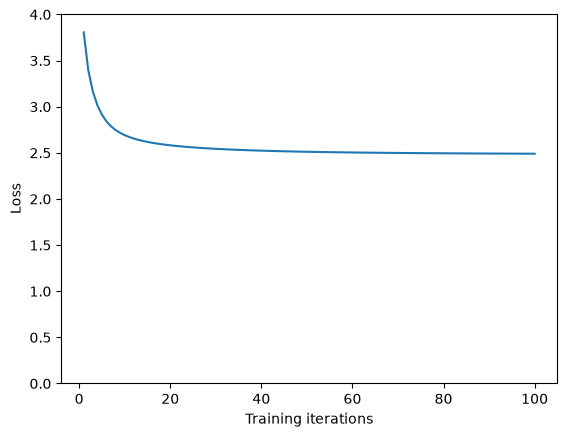

In [17]:
import numpy as np

plt.plot(np.arange(1,len(loses)+1),loses)
plt.xlabel("Training iterations")
plt.ylabel("Loss")
plt.ylim(0, max(loses)+ 0.2)

In [18]:
# Sample from NN to make more names
g = torch.Generator().manual_seed(67)

for i in range(10):

    out = []
    ix = 0
    while True:

        xenc = F.one_hot(torch.tensor([ix]), num_classes=27).float()
        logits = xenc @ W
        counts = logits.exp()
        p = counts / counts.sum(dim=1,keepdims=True)

        ix = torch.multinomial(p, num_samples=1, replacement=True, generator=g).item()
        out.append(itos[ix])
        if ix==0:
            break

    print("".join(out))

jalellin.
h.
ntiy.
tisaluliazfbeexujkenni.
guin.
nnnusly.
je.
janoneceleashariba.
amynn.
s.


Notice, these outputs are *nearly exactly* the same as the prediction above!

**Softmax function**  
Used to output something which is probability-like. Neurons output log counts, logits, which the neuron output.
$$\frac{e^{z_i}}{\sum_{j=1}^K e^{z_j}}$$
This is a useful way to trasform the neuron outputs into something which is probability-like.